/var/folders/1l/ft13x8qx2rbbb5k4n7qs_g740000gn/T/ipykernel_1498/3640739536.py:31: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  tempa[idx] = temp[(y==yy)*(m==8)]-temp_clim[8-1]


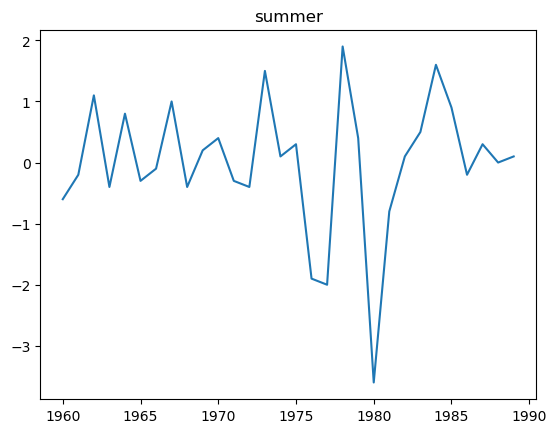

/var/folders/1l/ft13x8qx2rbbb5k4n7qs_g740000gn/T/ipykernel_1498/3640739536.py:45: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  tempa[idx] = temp[(y==yy)*(m==12)]-temp_clim[12-1]


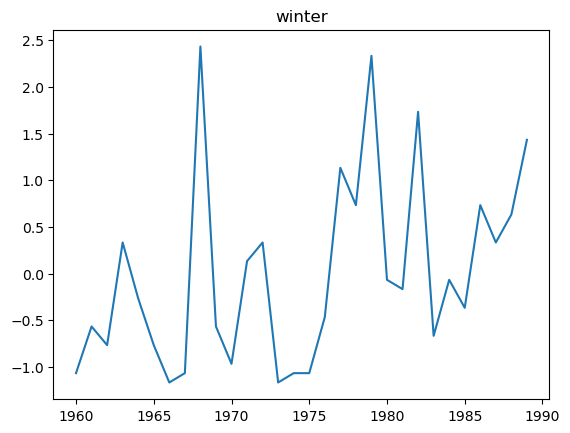

In [1]:
# question A
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

tokyo_temp = np.genfromtxt("Tokyo_temp.csv", 
                           delimiter=",", 
                           usecols=(0, 1, 2)
                          )

y = tokyo_temp[:, 0]
m = tokyo_temp[:, 1]
temp = tokyo_temp[:, 2]

temp = temp[(1960 <= y)*(y <= 1989)]
m = m[(1960 <= y)*(y <= 1989)]
y = y[(1960 <= y)*(y <= 1989)]

month = np.arange(1, 13, 1)
temp_clim = np.zeros((12))
for mm in range(1, 13):
    temp_clim[mm-1] = np.nanmean(temp[m==mm], 0)


# 夏
mon = np.arange(1960, 1990, 1)
tmt = temp.shape
tempa = np.zeros((30))
idx = 0
for yy in range(1960, 1990):
    tempa[idx] = temp[(y==yy)*(m==8)]-temp_clim[8-1]
    idx+=1

plt.title("summer")
plt.plot(mon,tempa)
plt.show()

# winter
plt.figure()
mon = np.arange(1960, 1990, 1)
tmt = temp.shape
tempa = np.zeros((30))
idx = 0
for yy in range(1960, 1990):
    tempa[idx] = temp[(y==yy)*(m==12)]-temp_clim[12-1]
    idx+=1

plt.title("winter")
plt.plot(mon,tempa)
plt.show()



**問題Aについて**<br>
8月を夏に設定した、12月を冬に設定した<br>
*冷夏*：1980<br>
*猛暑*：1978<br>
*暖冬*：1968、1979<br>
*寒冬*：1966-1967、1973-1975、1984<br>

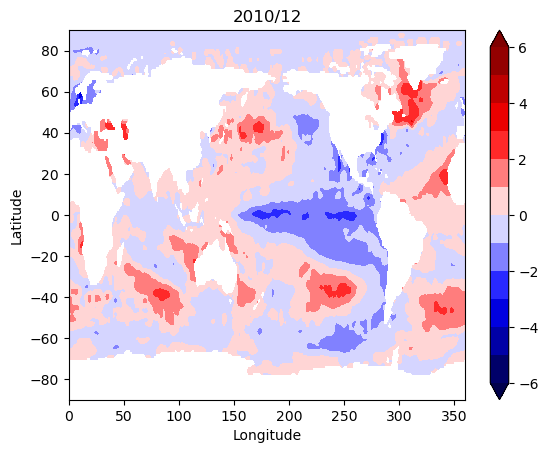

In [2]:
# question B
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

loadfile1 = 'sst_OISST.npz'
sst_dataset = np.load(loadfile1)
sst = sst_dataset['sst']
lon2 = sst_dataset['lon2']
lat2 = sst_dataset['lat2']
y = sst_dataset['y']
m = sst_dataset['m']

loadfile2 = 'sstc_OISST.npz'
sstc_dataset = np.load(loadfile2)
sst_clim = sstc_dataset['sst_clim']

[imt, jmt ,tmt] = sst.shape
ssta = np.zeros((imt, jmt, tmt))
for yy in range(1982, 2020):
    for mm in range(1, 13):
        ssta[:, :, (y==yy)*(m==mm)] = sst[:, :, (y==yy)*(m==mm)] - (sst_clim[:, :, mm-1])[:, :, np.newaxis]

draw_year = 2010
draw_month = 12

vmin = -6
vmax = 6
vint = 1

plt.figure()
cm = plt.get_cmap('seismic')
cs = plt.contourf(lon2, lat2, 
                  np.squeeze(ssta[:, :, (y==draw_year)*(m==draw_month)]), 
                  cmap=cm, norm=Normalize(vmin=vmin, vmax=vmax),
                  levels=np.arange(vmin,vmax+vint,vint), extend='both')
plt.colorbar(cs)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
title = str(draw_year) + '/' + str(draw_month)
plt.title(title)
plt.xlim(0, 360)
plt.ylim(-90, 90)
plt.show()

問題Bについて<br>赤道付近の太平洋中部から東部にかけての海域、この青い帯状の領域は、海面水温が平年と比べて異常に低くなっていることを示しています。

**問題Cについて<br>**
*１月を例にする*：<br>
気候値：$x = \frac{x_1+x_2+\cdots+x_{30}}{30}$<br>
偏差：$x_1-x$, $x_2-x$ ... $x_{30}-x$<br>
偏差の平均：$\frac{x_1-x+x_2-x+\cdots+x_{30}-x}{30}$ = $\frac{x_1+x_2+\cdots+x_{30}}{30} + \frac{(-x-x-\cdots-x)}{30}$ = $x - \frac{30x}{30}$ = $x - x$ = $0$

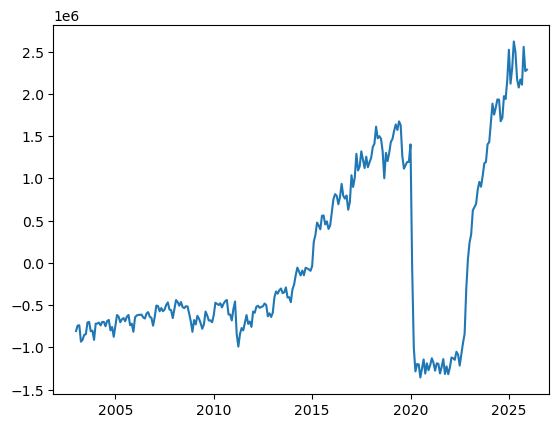

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 读取刚刚上传的 Excel 文件
filepath = "20261021_1615-5.xlsx"
xls = pd.ExcelFile(filepath)

years = []
months = []
visitors = []

# 自动遍历从 2003 到 2026 年的所有 Sheet
for sheet in reversed(xls.sheet_names):
    year = int(sheet)
    # header=3 表示跳过前3行没用的表头，直接用“1月, 2月...”作为列名读取
    df = pd.read_excel(filepath, sheet_name=sheet, header=3)
    
    # 找到第一列为“総数”的那一行
    total_row = df[df.iloc[:, 0] == '総数']
    
    if not total_row.empty:
        for mm in range(1, 13):
            col_name = f"{mm}月"
            if col_name in df.columns:
                val = total_row[col_name].values[0]
                # 排除掉未来还没有发生（数据为空）的月份
                if not pd.isna(val):
                    years.append(year)
                    months.append(mm)
                    visitors.append(val)
# !pip install openpyxl 下载openpyxl 这个库。Pandas 在读取 .xlsx 格式的 Excel 文件时，必须依赖这个库来解析数据。
# 转换成 NumPy 数组格式
y = np.array(years)
m = np.array(months)
visit = np.array(visitors)

visit = visit[(2003 <= y)*(y <= 2025)]
m = m[(2003 <= y)*(y <= 2025)]
y = y[(2003 <= y)*(y <= 2025)]

month = np.arange(1, 13, 1)
visit_clim = np.zeros((12))
for mm in range(1, 13):
    visit_clim[mm-1] = np.nanmean(visit[m==mm], 0)

mon = np.arange(2003, 2026, 1/12)
tmt = visit.shape
visita = np.zeros((276))
for yy in range(2003, 2026):
    for mm in range(1, 13):
        visita[(y==yy)*(m==mm)] = visit[(y==yy)*(m==mm)] - visit_clim[mm-1]

plt.plot(mon,visita)
plt.show()

グラフの偏差から、訪日外客数の顕著な変化とその理由が読み取れます。<br>
まず、2011年の落ち込みは東日本大震災の影響です。その後、2013年から2019年にかけては、ビザ要件の緩和や円安によって観光客が急増しました。<br>
一方、2020年から2022年の記録的な急落は、新型コロナウイルスの流行と厳しい水際対策が原因です。そして2023年以降は、コロナ後の旅行需要の回復と歴史的な円安により、過去最高水準まで急激に回復しています。<br>